=== MULTI-TASK NEURAL NETWORK: COMPLETE IMPLEMENTATION ===
✅ Serial numbers dropped | ✅ Dimensions fixed | 🎓 Senior presentation ready

✅ Data shapes: X=(16000, 20), y_cls=(16000,), y_reg=(16000,)
✅ Train/Val split: 12800 / 3200 samples

🚀 Training started...

Epoch    0 | Loss 56.0437 | Train Acc 0.023 | Val Acc 0.028 | F1 0.013 | R² -13.141
Epoch  100 | Loss 7.1691 | Train Acc 0.574 | Val Acc 0.562 | F1 0.547 | R² -0.443
Epoch  200 | Loss 3.8551 | Train Acc 0.701 | Val Acc 0.682 | F1 0.674 | R² 0.297
Epoch  300 | Loss 2.7968 | Train Acc 0.754 | Val Acc 0.732 | F1 0.728 | R² 0.518
Epoch  400 | Loss 2.1972 | Train Acc 0.788 | Val Acc 0.775 | F1 0.773 | R² 0.640
Epoch  500 | Loss 1.7838 | Train Acc 0.813 | Val Acc 0.793 | F1 0.791 | R² 0.723
Epoch  600 | Loss 1.4650 | Train Acc 0.831 | Val Acc 0.809 | F1 0.808 | R² 0.787
Epoch  700 | Loss 1.2139 | Train Acc 0.843 | Val Acc 0.823 | F1 0.822 | R² 0.839
Epoch  800 | Loss 1.0134 | Train Acc 0.854 | Val Acc 0.834 | F1 0.833 | R² 0.880
Epoch 

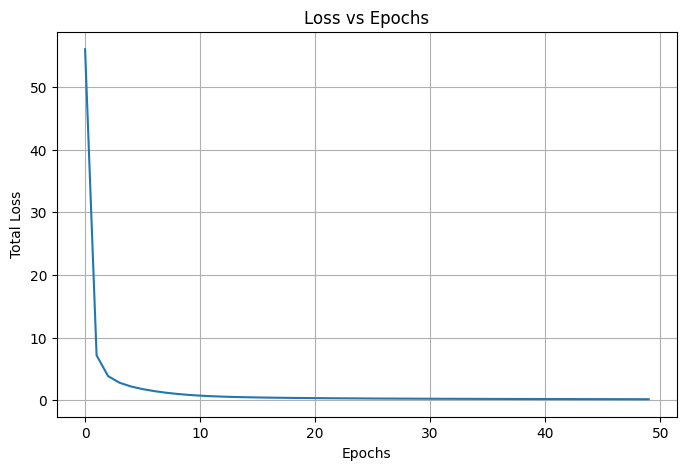

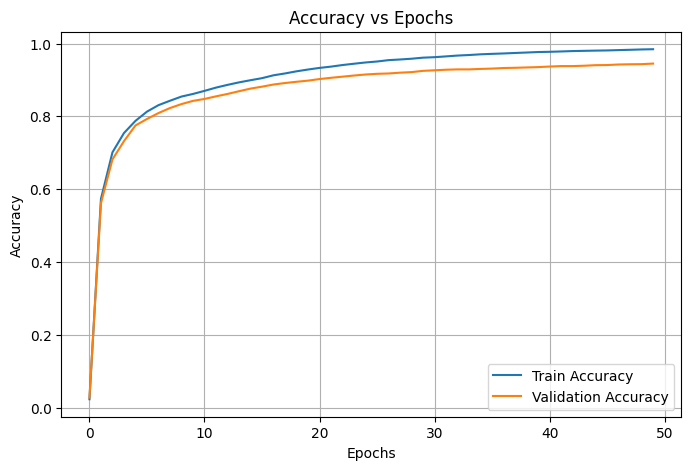


Test predictions saved: test_predictions.csv


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

                 # DATA LOADING & CLEANING

train = pd.read_csv("train_nn.csv")
test = pd.read_csv("test_nn.csv")

train.drop(columns=["Unnamed: 0"], inplace=True)
test.drop(columns=["Unnamed: 0"], inplace=True)

X = train.drop(columns=["target_cls", "target_reg"]).values
y_cls_raw = train["target_cls"].values
y_reg = train["target_reg"].values
X_test = test.values

print(f"✅ Data shapes: X={X.shape}, y_cls={y_cls_raw.shape}, y_reg={y_reg.shape}")

# Label encoding
classes = np.unique(y_cls_raw)
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
y_cls = np.array([class_to_idx[c] for c in y_cls_raw])
num_classes = len(classes)

# Normalization
mean, std = X.mean(axis=0), X.std(axis=0) + 1e-8
X_norm = (X - mean) / std
X_test_norm = (X_test - mean) / std

# Train/Validation split
np.random.seed(42)
idx = np.random.permutation(len(X_norm))
split = int(0.8 * len(X_norm))

X_train, X_val = X_norm[idx[:split]], X_norm[idx[split:]]
y_cls_train, y_cls_val = y_cls[idx[:split]], y_cls[idx[split:]]
y_reg_train, y_reg_val = y_reg[idx[:split]], y_reg[idx[split:]]

print(f"✅ Train/Val split: {len(X_train)} / {len(X_val)} samples\n")


#                             UTILITY FUNCTIONS

def relu(z): return np.maximum(0, z)
def relu_grad(z): return (z > 0).astype(float)

def softmax(z):
    z -= np.max(z, axis=1, keepdims=True)
    return np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True)

def one_hot(y, c): return np.eye(c)[y]

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def macro_f1(y_true, y_pred):
    f1 = 0
    for c in np.unique(y_true):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))
        p = tp / (tp + fp) if tp + fp > 0 else 0
        r = tp / (tp + fn) if tp + fn > 0 else 0
        f1 += 2*p*r / (p+r) if p+r > 0 else 0
    return f1 / len(np.unique(y_true))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - y_true.mean())**2)
    return 1 - ss_res / ss_tot


#                              MODEL ARCHITECTURE

input_dim, hidden_dim = X.shape[1], 128
scale = np.sqrt(2 / (input_dim + hidden_dim))

W1 = np.random.randn(input_dim, hidden_dim) * scale
b1 = np.zeros(hidden_dim)

W_cls = np.random.randn(hidden_dim, num_classes) * scale * 0.5
b_cls = np.zeros(num_classes)

W_reg = np.random.randn(hidden_dim, 1) * scale * 0.5
b_reg = np.zeros(1)

# Adam states
adam = {}
for p in ["W1","b1","W_cls","b_cls","W_reg","b_reg"]:
    adam["m"+p] = np.zeros_like(eval(p))
    adam["v"+p] = np.zeros_like(eval(p))

# Hyperparameters
lr = 0.001
weight_decay = 1e-4
beta1, beta2, eps = 0.9, 0.999, 1e-8
epochs = 5000

# Class balancing
cls_counts = np.bincount(y_cls_train, minlength=num_classes)
cls_weights = len(y_cls_train) / (num_classes * cls_counts + 1e-8)
y_cls_oh = one_hot(y_cls_train, num_classes)
y_cls_oh_weighted = y_cls_oh * cls_weights

# Tracking
loss_history = []
train_acc_history = []
val_acc_history = []

print("🚀 Training started...\n")
t = 0
best_f1 = 0

#                              TRAINING LOOP

for epoch in range(epochs):
    t += 1

    # Forward
    z1 = X_train @ W1 + b1
    h = relu(z1)

    logits = h @ W_cls + b_cls
    probs = softmax(logits)

    reg_out = (h @ W_reg + b_reg).flatten()

    # Loss
    cls_loss = -np.mean(np.sum(y_cls_oh_weighted * np.log(probs + 1e-8), axis=1))
    reg_loss = np.mean((reg_out - y_reg_train)**2)
    l2 = 0.5 * weight_decay * (np.sum(W1**2) + np.sum(W_cls**2) + np.sum(W_reg**2))
    loss = cls_loss + reg_loss + l2

    # Train accuracy
    train_preds = np.argmax(probs, axis=1)
    train_acc = accuracy(y_cls_train, train_preds)

    # Backprop
    d_logits = (probs - y_cls_oh) / len(X_train)
    d_reg = 2 * (reg_out - y_reg_train) / len(X_train)

    dW_cls = h.T @ d_logits + weight_decay * W_cls
    db_cls = d_logits.sum(axis=0)

    dW_reg = h.T @ d_reg[:,None] + weight_decay * W_reg
    db_reg = d_reg.sum()

    dh = d_logits @ W_cls.T + d_reg[:,None] @ W_reg.T
    dz1 = dh * relu_grad(z1)

    dW1 = X_train.T @ dz1 + weight_decay * W1
    db1 = dz1.sum(axis=0)

                             # Adam update
    def adam_step(p, dp):
        m = adam["m"+p] = beta1*adam["m"+p] + (1-beta1)*dp
        v = adam["v"+p] = beta2*adam["v"+p] + (1-beta2)*(dp**2)
        mhat = m / (1-beta1**t)
        vhat = v / (1-beta2**t)
        return eval(p) - lr * mhat / (np.sqrt(vhat) + eps)

    W1 = adam_step("W1", dW1)
    b1 = adam_step("b1", db1)
    W_cls = adam_step("W_cls", dW_cls)
    b_cls = adam_step("b_cls", db_cls)
    W_reg = adam_step("W_reg", dW_reg)
    b_reg = adam_step("b_reg", db_reg)

                                   # Validation
    if epoch % 100 == 0:
        h_val = relu(X_val @ W1 + b1)
        val_probs = softmax(h_val @ W_cls + b_cls)
        val_preds = np.argmax(val_probs, axis=1)
        val_reg = (h_val @ W_reg + b_reg).flatten()

        val_acc = accuracy(y_cls_val, val_preds)
        val_f1 = macro_f1(y_cls_val, val_preds)
        val_r2 = r2_score(y_reg_val, val_reg)

        print(f"Epoch {epoch:4d} | Loss {loss:.4f} | "
              f"Train Acc {train_acc:.3f} | Val Acc {val_acc:.3f} | "
              f"F1 {val_f1:.3f} | R² {val_r2:.3f}")

        loss_history.append(loss)
        train_acc_history.append(train_acc)
        val_acc_history.append(val_acc)


                            # VISUALIZATION

plt.figure(figsize=(8,5))
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Total Loss")
plt.title("Loss vs Epochs")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(train_acc_history, label="Train Accuracy")
plt.plot(val_acc_history, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epochs")
plt.legend()
plt.grid(True)
plt.show()

                       #TEST PREDICTIONS

h_test = relu(X_test_norm @ W1 + b1)
test_probs = softmax(h_test @ W_cls + b_cls)
test_cls = np.argmax(test_probs, axis=1)
test_reg = (h_test @ W_reg + b_reg).flatten()

test_cls_original = np.array([classes[i] for i in test_cls])

np.savetxt(
    "test_predictions.csv",
    np.column_stack([test_cls_original, test_reg]),
    delimiter=",",
    fmt="%d,%.6f",
    header="target_cls,target_reg",
    comments=""
)

print("\nTest predictions saved: test_predictions.csv")
